# Dhaka Obesity Dataset: Full Analysis Pipeline

**Steps:** 1) Load → 2) Inspect → 3) Clean → 4) Feature engineering → 5) EDA → 6) Preprocessing → 7) Modeling → 8) Evaluation → 9) Feature importance → 10) Save outputs

**How to use:** put `Dhaka_Obesity.csv` in the same folder as this notebook, then choose **Run → Run All Cells**.

## 0. Setup (run once, then restart the kernel)

In [4]:
import sys
print("Python:", sys.version.split()[0])
print("Interpreter:", sys.executable)
%pip install --quiet numpy pandas matplotlib seaborn scikit-learn scipy joblib
print("Done. Now restart the kernel (Kernel > Restart) and run from Cell 1 onward.")

Python: 3.9.6
Interpreter: /Library/Developer/CommandLineTools/usr/bin/python3
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.
Done. Now restart the kernel (Kernel > Restart) and run from Cell 1 onward.


## 1. Imports and settings

In [5]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 50)
RANDOM_STATE = 42

os.makedirs("outputs", exist_ok=True)   # all saved files go here

## 2. Load the data

In [6]:
FILE_NAME = "Dhaka_Obesity.csv"

# Your file location comes first; the other paths are just fallbacks
candidates = ["/Users/thaminurhossan/Downloads/Dhaka_Obesity.csv",
              FILE_NAME,
              os.path.join(os.path.expanduser("~"), "Downloads", FILE_NAME),
              os.path.join("..", FILE_NAME)]
path = next((p for p in candidates if os.path.exists(p)), None)
if path is None:
    raise FileNotFoundError(f"Could not find {FILE_NAME}. Check the path in the candidates list.")

df_raw = pd.read_csv(path)
print("Loaded from:", path)
print("Shape:", df_raw.shape)
df_raw.head()

Loaded from: /Users/thaminurhossan/Downloads/Dhaka_Obesity.csv
Shape: (2182, 17)


,Gender,Age,Height (m),Weight (kg),Family history of overweight,High caloric food consumption,Vegetable consumption frequency,Daily main meals frequency,Between-meal food consumption frequency,Smoking,Alcohol intake,Daily water intake,Monitor calories,Physical exercise,Daily device usage duration,Mode of transportation,Obesity level
0,Male,29,1.65,101.0,Yes,Yes,Sometimes,Three,Frequently,No,I do not drink,Between 1 and 2 L,No,I do not have,More than 5 hours,Private Car,Obesity_Type_II
1,Female,25,1.65,53.0,No,No,Always,Three,Always,No,I do not drink,Between 1 and 2 L,No,Almost Everyday,More than 5 hours,Public Transportation,Normal_Weight
2,Male,23,1.70,70.0,No,No,Always,Between 1-2,Sometimes,Yes,Sometimes,Less than a liter,No,I do not have,More than 5 hours,Public Transportation,Normal_Weight
3,Male,22,1.68,112.0,Yes,Yes,Sometimes,Three,Frequently,No,I do not drink,Between 1 and 2 L,No,I do not have,More than 5 hours,Public Transportation,Obesity_Type_II
4,Male,19,1.75,67.0,No,Yes,Always,Three,Sometimes,Yes,I do not drink,Between 1 and 2 L,No,2 or 4 days,3-5 hours,Bike,Normal_Weight


## 3. Initial inspection

In [7]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2182 entries, 0 to 2181
Data columns (total 17 columns):
 #   Column                                   Non-Null Count  Dtype  
---  ------                                   --------------  -----  
 0   Gender                                   2182 non-null   object 
 1   Age                                      2182 non-null   int64  
 2   Height (m)                               2182 non-null   float64
 3   Weight (kg)                              2182 non-null   float64
 4   Family history of overweight             2182 non-null   object 
 5   High caloric food consumption            2182 non-null   object 
 6   Vegetable consumption frequency          2182 non-null   object 
 7   Daily main meals frequency               2182 non-null   object 
 8   Between-meal food consumption frequency  2182 non-null   object 
 9   Smoking                                  2182 non-null   object 
 10  Alcohol intake                           2182 no

In [8]:
print("Missing values per column:")
print(df_raw.isna().sum()[lambda s: s > 0] if df_raw.isna().any().any() else "None")
print("\nExact duplicate rows:", df_raw.duplicated().sum())
df_raw.describe().T

Missing values per column:
None

Exact duplicate rows: 25


,count,mean,std,min,25%,50%,75%,max
Age,2182.0,26.752062,8.425983,15.00,22.00,24.00,28.0,75.00
Height (m),2182.0,1.627635,0.101239,1.22,1.57,1.63,1.7,1.88
Weight (kg),2182.0,73.814207,20.837370,35.00,56.00,72.00,89.0,150.00


In [9]:
# Unique values of every categorical column (helps decide encodings)
cat_cols_raw = df_raw.select_dtypes(exclude="number").columns
for c in cat_cols_raw:
    print(f"{c}: {sorted(df_raw[c].unique())}")

Gender: ['Female', 'Male']
Family history of overweight: ['No', 'Yes']
High caloric food consumption: ['No', 'Yes']
Vegetable consumption frequency: ['Always', 'Never', 'Sometimes']
Daily main meals frequency: ['Between 1-2', 'More than Three', 'Three']
Between-meal food consumption frequency: ['Always', 'Frequently', 'No', 'Sometimes']
Smoking: ['No', 'Yes']
Alcohol intake: ['Always', 'Frequently', 'I do not drink', 'Sometimes']
Daily water intake: ['Between 1 and 2 L', 'Less than a liter', 'More than 2 L']
Monitor calories: ['No', 'Yes']
Physical exercise: ['1 or 2 days', '2 or 4 days', '4 or 5 days', 'Almost Everyday', 'I do not have']
Daily device usage duration: ['0-2 hours', '3-5 hours', 'More than 5 hours']
Mode of transportation: ['Bike', 'Private Car', 'Public Transportation', 'Rickshaw', 'Walking']
Obesity level: ['Insufficient_Weight', 'Normal_Weight', 'Obesity_Type_I', 'Obesity_Type_II', 'Obesity_Type_III', 'Overweight']


## 4. Cleaning

- strip stray whitespace in text columns
- remove exact duplicate rows
- check for impossible values (age, height, weight)

In [10]:
df = df_raw.copy()

# 4.1 Strip whitespace in text columns
for c in df.select_dtypes(exclude="number").columns:
    df[c] = df[c].astype(str).str.strip()

# 4.2 Drop exact duplicates
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df)} duplicate rows -> {len(df)} rows remain")

# 4.3 Plausibility checks
print("\nAge range    :", df["Age"].min(), "-", df["Age"].max())
print("Height range :", df["Height (m)"].min(), "-", df["Height (m)"].max(), "m")
print("Weight range :", df["Weight (kg)"].min(), "-", df["Weight (kg)"].max(), "kg")

bad = df[(df["Height (m)"] < 1.0) | (df["Height (m)"] > 2.3) |
         (df["Weight (kg)"] < 25) | (df["Weight (kg)"] > 300) |
         (df["Age"] < 10) | (df["Age"] > 100)]
print("Rows with implausible values:", len(bad))
df = df.drop(bad.index).reset_index(drop=True)

Removed 25 duplicate rows -> 2157 rows remain

Age range    : 15 - 75
Height range : 1.22 - 1.88 m
Weight range : 35.0 - 150.0 kg
Rows with implausible values: 0


In [11]:
# 4.4 Outlier check on Age (IQR rule). Flagged, not removed, since they are valid people.
q1, q3 = df["Age"].quantile([0.25, 0.75])
iqr = q3 - q1
upper = q3 + 1.5 * iqr
print(f"Age IQR upper fence: {upper:.1f}; rows above it: {(df['Age'] > upper).sum()}")

Age IQR upper fence: 37.0; rows above it: 239


## 5. Feature engineering: BMI

BMI = weight (kg) / height (m)². The obesity categories in this dataset follow the standard BMI cut-offs, so we compute BMI and verify that the labels match.

In [12]:
df["BMI"] = df["Weight (kg)"] / df["Height (m)"] ** 2

level_order = ["Insufficient_Weight", "Normal_Weight", "Overweight",
               "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
df["Obesity level"] = pd.Categorical(df["Obesity level"], categories=level_order, ordered=True)

# BMI range inside each class
df.groupby("Obesity level", observed=True)["BMI"].agg(["count", "min", "max", "mean"]).round(1)

,count,min,max,mean
Obesity level,,,,
Insufficient_Weight,359,11.7,18.4,17.3
Normal_Weight,529,18.5,25.0,22.1
Overweight,419,25.0,30.0,27.2
Obesity_Type_I,317,30.0,35.0,32.2
Obesity_Type_II,283,35.0,39.9,37.1
Obesity_Type_III,250,40.0,54.6,43.5


In [13]:
# How well do the standard WHO BMI cut-offs reproduce the labels?
def bmi_to_level(b):
    if b < 18.5: return "Insufficient_Weight"
    if b < 25:   return "Normal_Weight"
    if b < 30:   return "Overweight"
    if b < 35:   return "Obesity_Type_I"
    if b < 40:   return "Obesity_Type_II"
    return "Obesity_Type_III"

df["BMI_level_check"] = df["BMI"].apply(bmi_to_level)
match = (df["BMI_level_check"] == df["Obesity level"].astype(str)).mean()
print(f"Labels matching WHO BMI cut-offs: {match:.1%}")
df = df.drop(columns="BMI_level_check")

Labels matching WHO BMI cut-offs: 99.9%


## 6. Exploratory data analysis

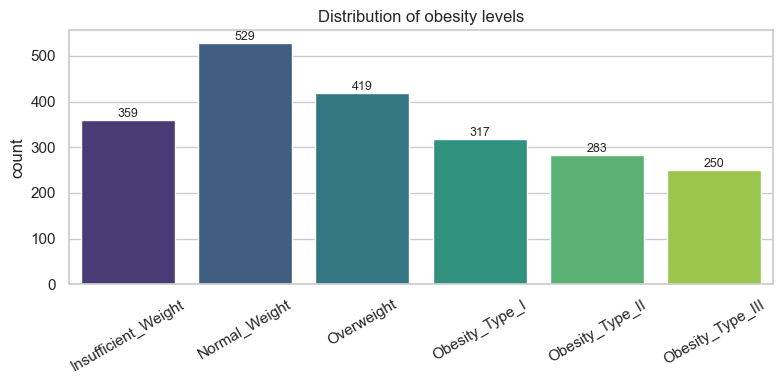

In [14]:
fig, ax = plt.subplots(figsize=(8, 4))
order = level_order
sns.countplot(data=df, x="Obesity level", order=order, palette="viridis", ax=ax)
ax.set_title("Distribution of obesity levels")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=30)
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/target_distribution.png", dpi=150)
plt.show()

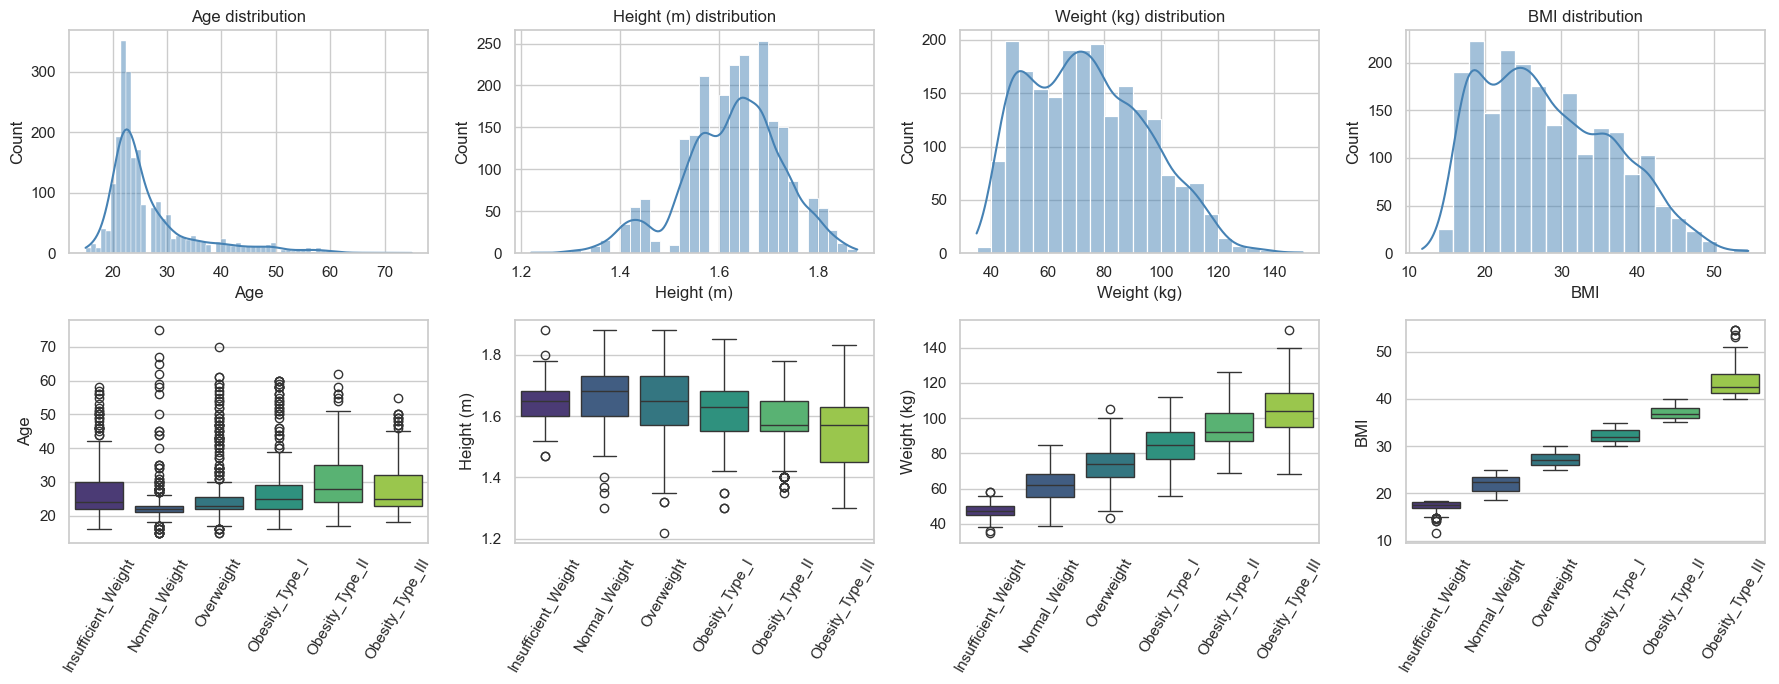

In [15]:
num_cols = ["Age", "Height (m)", "Weight (kg)", "BMI"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for i, c in enumerate(num_cols):
    sns.histplot(df[c], kde=True, ax=axes[0, i], color="steelblue")
    axes[0, i].set_title(f"{c} distribution")
    sns.boxplot(data=df, x="Obesity level", y=c, order=order, ax=axes[1, i], palette="viridis")
    axes[1, i].tick_params(axis="x", rotation=60)
    axes[1, i].set_xlabel("")
plt.tight_layout()
plt.savefig("outputs/numeric_distributions.png", dpi=150)
plt.show()

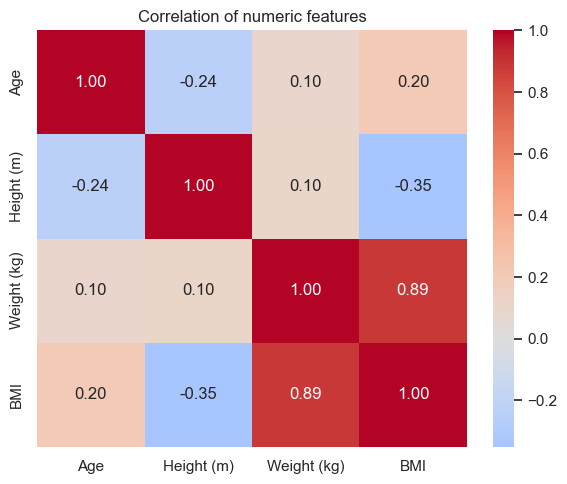

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(df[num_cols].corr(), annot=True, cmap="coolwarm", center=0, fmt=".2f", ax=ax)
ax.set_title("Correlation of numeric features")
plt.tight_layout()
plt.show()

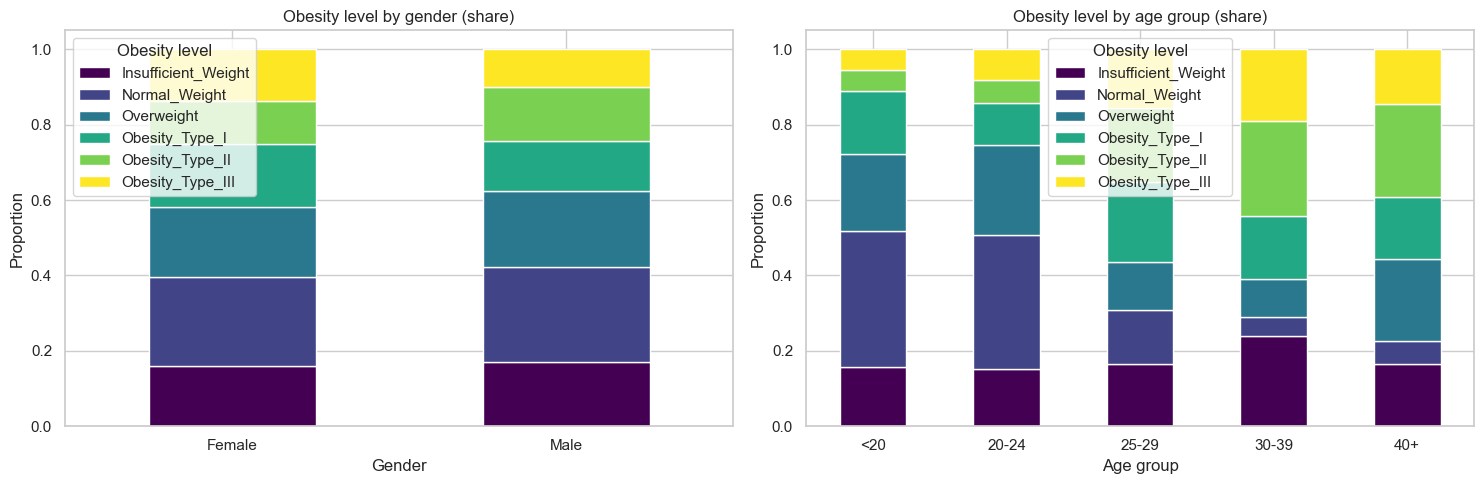

In [17]:
# Obesity level by gender and age group
df["Age group"] = pd.cut(df["Age"], bins=[0, 19, 24, 29, 39, 120],
                         labels=["<20", "20-24", "25-29", "30-39", "40+"])

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
pd.crosstab(df["Gender"], df["Obesity level"], normalize="index")[level_order] \
    .plot(kind="bar", stacked=True, colormap="viridis", ax=axes[0])
axes[0].set_title("Obesity level by gender (share)")
axes[0].set_ylabel("Proportion"); axes[0].tick_params(axis="x", rotation=0)

pd.crosstab(df["Age group"], df["Obesity level"], normalize="index")[level_order] \
    .plot(kind="bar", stacked=True, colormap="viridis", ax=axes[1])
axes[1].set_title("Obesity level by age group (share)")
axes[1].set_ylabel("Proportion"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout()
plt.savefig("outputs/gender_age_vs_obesity.png", dpi=150)
plt.show()

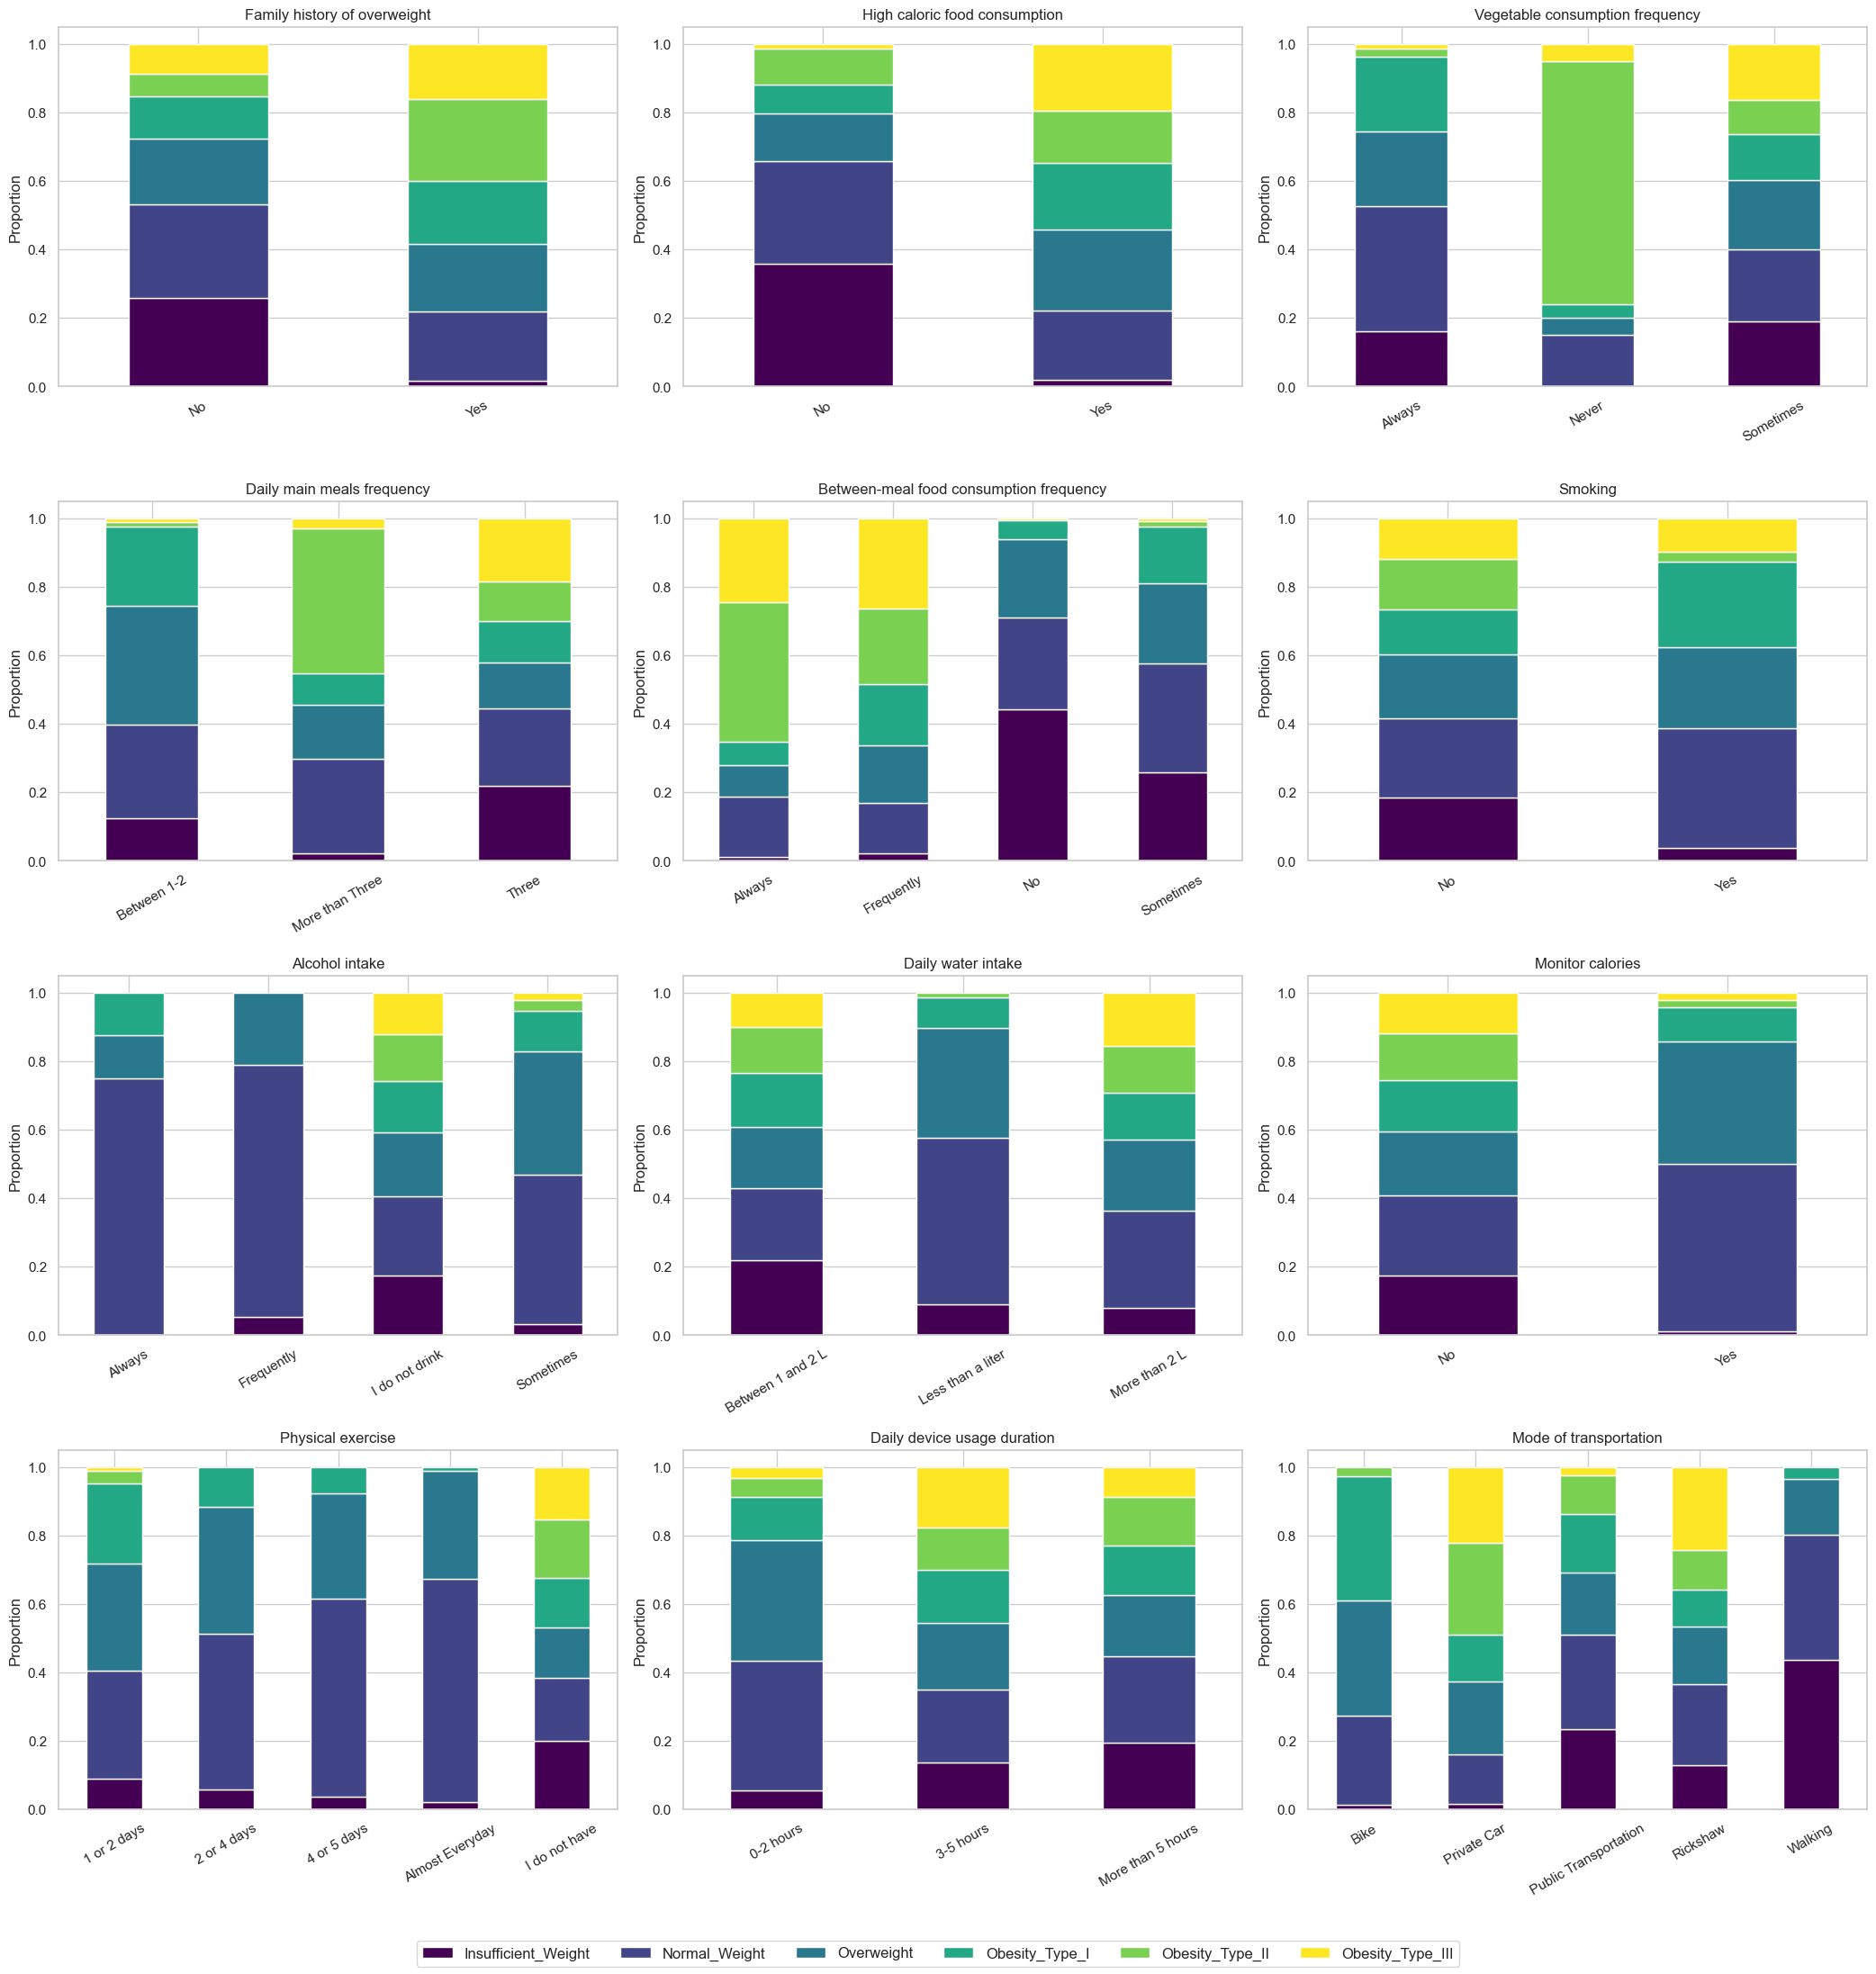

In [18]:
# Every lifestyle / habit column versus obesity level (share within each category)
habit_cols = ["Family history of overweight", "High caloric food consumption",
              "Vegetable consumption frequency", "Daily main meals frequency",
              "Between-meal food consumption frequency", "Smoking", "Alcohol intake",
              "Daily water intake", "Monitor calories", "Physical exercise",
              "Daily device usage duration", "Mode of transportation"]

fig, axes = plt.subplots(4, 3, figsize=(21, 22))
for ax, c in zip(axes.ravel(), habit_cols):
    ct = pd.crosstab(df[c], df["Obesity level"], normalize="index")[level_order]
    ct.plot(kind="bar", stacked=True, colormap="viridis", ax=ax, legend=False)
    ax.set_title(c); ax.set_xlabel(""); ax.set_ylabel("Proportion")
    ax.tick_params(axis="x", rotation=30)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=6, fontsize=12)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig("outputs/habits_vs_obesity.png", dpi=120)
plt.show()

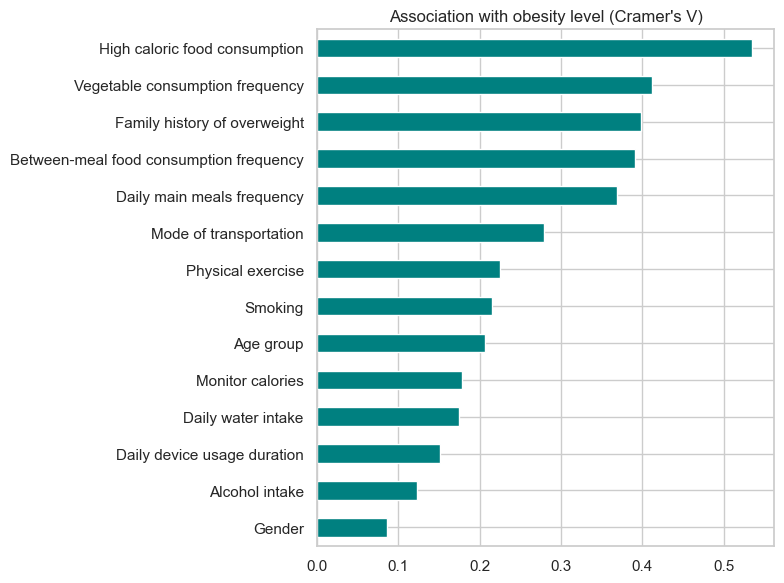

High caloric food consumption              0.535
Vegetable consumption frequency            0.412
Family history of overweight               0.398
Between-meal food consumption frequency    0.391
Daily main meals frequency                 0.369
Mode of transportation                     0.279
Physical exercise                          0.225
Smoking                                    0.215
Age group                                  0.206
Monitor calories                           0.178
Daily water intake                         0.175
Daily device usage duration                0.152
Alcohol intake                             0.122
Gender                                     0.086
dtype: float64

In [19]:
# Statistical association: Cramer's V between each habit and obesity level (0 = none, 1 = perfect)
from scipy.stats import chi2_contingency

def cramers_v(x, y):
    ct = pd.crosstab(x, y)
    chi2 = chi2_contingency(ct)[0]
    n = ct.values.sum()
    r, k = ct.shape
    return np.sqrt((chi2 / n) / (min(r, k) - 1))

assoc = pd.Series({c: cramers_v(df[c], df["Obesity level"]) for c in habit_cols + ["Gender", "Age group"]})
assoc = assoc.sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
assoc.plot(kind="barh", color="teal", ax=ax)
ax.set_title("Association with obesity level (Cramer's V)")
plt.tight_layout()
plt.savefig("outputs/cramers_v.png", dpi=150)
plt.show()
assoc.sort_values(ascending=False).round(3)

## 7. Preprocessing for modeling

**Important:** the target label is computed directly from BMI (height and weight), so a model that sees height and weight can reach ~100% accuracy trivially. To get something informative, we train two setups:

- **Model A (full):** includes Height, Weight, BMI. Shows the upper bound and confirms the label is BMI-driven.
- **Model B (lifestyle only):** excludes Height, Weight, BMI. Answers the real question: *how well do habits and demographics predict obesity level?*

Encoding:
- ordered categories (frequency, water intake, etc.) → ordinal integers that keep the order
- unordered categories (gender, transport, etc.) → one-hot
- numeric → standardized

In [20]:
# Ordered categories, with their natural order
ordinal_maps = {
    "Vegetable consumption frequency":         ["Never", "Sometimes", "Always"],
    "Daily main meals frequency":              ["Between 1-2", "Three", "More than Three"],
    "Between-meal food consumption frequency": ["No", "Sometimes", "Frequently", "Always"],
    "Alcohol intake":                          ["I do not drink", "Sometimes", "Frequently", "Always"],
    "Daily water intake":                      ["Less than a liter", "Between 1 and 2 L", "More than 2 L"],
    "Physical exercise":                       ["I do not have", "1 or 2 days", "2 or 4 days", "4 or 5 days", "Almost Everyday"],
    "Daily device usage duration":             ["0-2 hours", "3-5 hours", "More than 5 hours"],
}
ordinal_cols = list(ordinal_maps.keys())
binary_cols  = ["Gender", "Family history of overweight", "High caloric food consumption",
                "Smoking", "Monitor calories"]
nominal_cols = ["Mode of transportation"]

target = "Obesity level"
y = df[target].astype(str)

def make_preprocessor(numeric_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("ord", OrdinalEncoder(categories=[ordinal_maps[c] for c in ordinal_cols]), ordinal_cols),
        ("bin", OneHotEncoder(drop="if_binary", handle_unknown="ignore"), binary_cols),
        ("nom", OneHotEncoder(handle_unknown="ignore"), nominal_cols),
    ])

features_A = ["Age", "Height (m)", "Weight (kg)", "BMI"] + ordinal_cols + binary_cols + nominal_cols
features_B = ["Age"] + ordinal_cols + binary_cols + nominal_cols
numeric_A  = ["Age", "Height (m)", "Weight (kg)", "BMI"]
numeric_B  = ["Age"]

# One split used by both setups (stratified keeps class proportions)
idx_train, idx_test = train_test_split(df.index, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
y_train, y_test = y.loc[idx_train], y.loc[idx_test]
print("Train:", len(idx_train), "| Test:", len(idx_test))

Train: 1725 | Test: 432


## 8. Model training and cross-validation

In [21]:
def get_models():
    return {
        "Logistic Regression": LogisticRegression(max_iter=2000, random_state=RANDOM_STATE),
        "Random Forest":       RandomForestClassifier(n_estimators=400, random_state=RANDOM_STATE, n_jobs=-1),
        "Gradient Boosting":   GradientBoostingClassifier(random_state=RANDOM_STATE),
    }

def run_experiment(name, feats, numeric):
    Xtr, Xte = df.loc[idx_train, feats], df.loc[idx_test, feats]
    cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
    rows, fitted = [], {}
    for mname, model in get_models().items():
        pipe = Pipeline([("prep", make_preprocessor(numeric)), ("model", model)])
        cv_acc = cross_val_score(pipe, Xtr, y_train, cv=cv, scoring="accuracy", n_jobs=-1)
        pipe.fit(Xtr, y_train)
        pred = pipe.predict(Xte)
        rows.append({"Setup": name, "Model": mname,
                     "CV accuracy (mean)": cv_acc.mean(), "CV accuracy (std)": cv_acc.std(),
                     "Test accuracy": accuracy_score(y_test, pred),
                     "Test macro-F1": f1_score(y_test, pred, average="macro")})
        fitted[mname] = pipe
    return pd.DataFrame(rows), fitted

res_A, fitted_A = run_experiment("A: full (with BMI)", features_A, numeric_A)
res_B, fitted_B = run_experiment("B: lifestyle only", features_B, numeric_B)
results = pd.concat([res_A, res_B], ignore_index=True)
results.round(4)

,Setup,Model,CV accuracy (mean),CV accuracy (std),Test accuracy,Test macro-F1
0,A: full (with BMI),Logistic Regression,0.9217,0.0207,0.9190,0.9192
1,A: full (with BMI),Random Forest,0.9872,0.0039,0.9861,0.9863
2,A: full (with BMI),Gradient Boosting,0.9959,0.0030,0.9977,0.9981
3,B: lifestyle only,Logistic Regression,0.5843,0.0400,0.6157,0.6240
4,B: lifestyle only,Random Forest,0.6330,0.0325,0.6273,0.6408
5,B: lifestyle only,Gradient Boosting,0.6278,0.0302,0.6597,0.6745


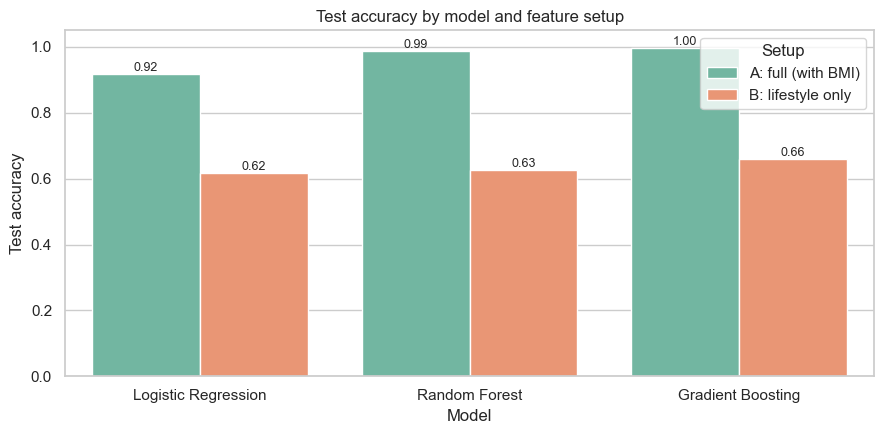

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.barplot(data=results, x="Model", y="Test accuracy", hue="Setup", palette="Set2", ax=ax)
ax.set_ylim(0, 1.05)
ax.set_title("Test accuracy by model and feature setup")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2, p.get_height()),
                    ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.savefig("outputs/model_comparison.png", dpi=150)
plt.show()

## 9. Evaluation of the best models

Best A: Gradient Boosting | Best B: Gradient Boosting 

=== Model A (Gradient Boosting): with height/weight/BMI ===
                     precision    recall  f1-score   support

Insufficient_Weight      0.986     1.000     0.993        72
      Normal_Weight      1.000     0.991     0.995       106
         Overweight      1.000     1.000     1.000        84
     Obesity_Type_I      1.000     1.000     1.000        63
    Obesity_Type_II      1.000     1.000     1.000        57
   Obesity_Type_III      1.000     1.000     1.000        50

           accuracy                          0.998       432
          macro avg      0.998     0.998     0.998       432
       weighted avg      0.998     0.998     0.998       432



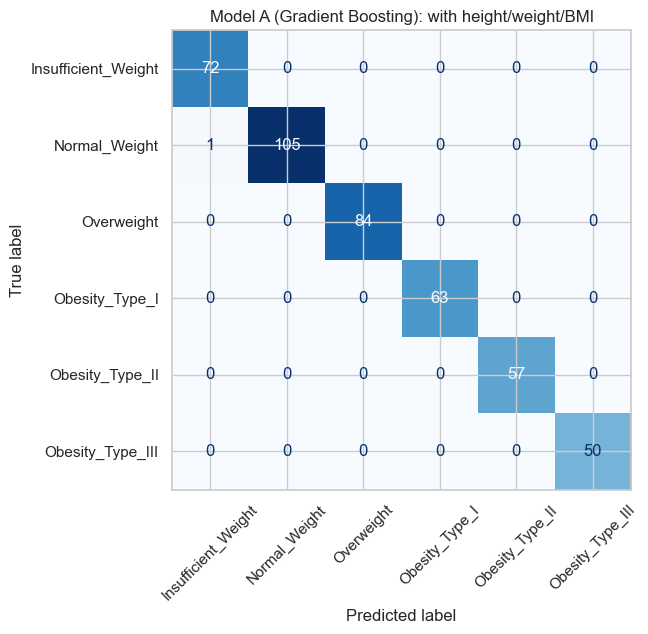

=== Model B (Gradient Boosting): lifestyle only ===
                     precision    recall  f1-score   support

Insufficient_Weight      0.805     0.917     0.857        72
      Normal_Weight      0.554     0.585     0.569       106
         Overweight      0.529     0.429     0.474        84
     Obesity_Type_I      0.633     0.603     0.618        63
    Obesity_Type_II      0.816     0.702     0.755        57
   Obesity_Type_III      0.705     0.860     0.775        50

           accuracy                          0.660       432
          macro avg      0.674     0.683     0.675       432
       weighted avg      0.655     0.660     0.654       432



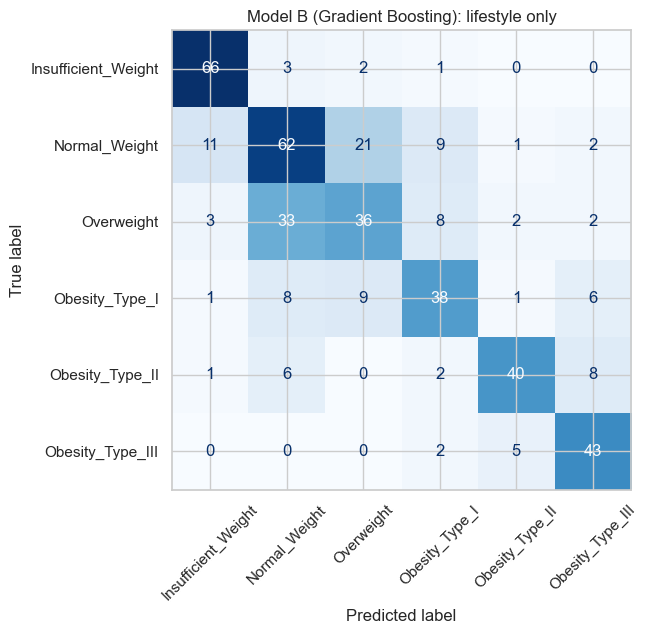

In [23]:
def evaluate(pipe, feats, title, fname):
    pred = pipe.predict(df.loc[idx_test, feats])
    print(f"=== {title} ===")
    print(classification_report(y_test, pred, labels=level_order, digits=3))
    cm = confusion_matrix(y_test, pred, labels=level_order)
    fig, ax = plt.subplots(figsize=(7.5, 6.5))
    ConfusionMatrixDisplay(cm, display_labels=level_order).plot(ax=ax, cmap="Blues", xticks_rotation=45, colorbar=False)
    ax.set_title(title)
    plt.tight_layout()
    plt.savefig(fname, dpi=150)
    plt.show()

best_A = res_A.sort_values("Test accuracy", ascending=False).iloc[0]["Model"]
best_B = res_B.sort_values("Test accuracy", ascending=False).iloc[0]["Model"]
print("Best A:", best_A, "| Best B:", best_B, "\n")

evaluate(fitted_A[best_A], features_A, f"Model A ({best_A}): with height/weight/BMI", "outputs/confusion_A.png")
evaluate(fitted_B[best_B], features_B, f"Model B ({best_B}): lifestyle only",        "outputs/confusion_B.png")

## 10. Feature importance (lifestyle-only model)

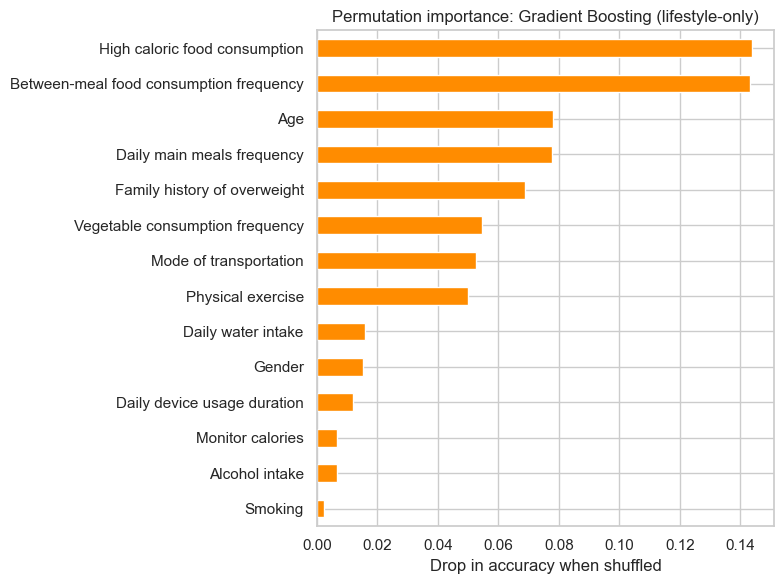

High caloric food consumption              0.1440
Between-meal food consumption frequency    0.1432
Age                                        0.0779
Daily main meals frequency                 0.0778
Family history of overweight               0.0690
Vegetable consumption frequency            0.0545
Mode of transportation                     0.0526
Physical exercise                          0.0498
Daily water intake                         0.0159
Gender                                     0.0153
Daily device usage duration                0.0120
Monitor calories                           0.0068
Alcohol intake                             0.0065
Smoking                                    0.0023
dtype: float64

In [24]:
pipe = fitted_B[best_B]
Xte_B = df.loc[idx_test, features_B]

# Permutation importance on the raw columns: how much does accuracy drop when a column is shuffled?
perm = permutation_importance(pipe, Xte_B, y_test, n_repeats=15, random_state=RANDOM_STATE,
                              scoring="accuracy", n_jobs=-1)
imp = pd.Series(perm.importances_mean, index=features_B).sort_values()

fig, ax = plt.subplots(figsize=(8, 6))
imp.plot(kind="barh", color="darkorange", ax=ax)
ax.set_title(f"Permutation importance: {best_B} (lifestyle-only)")
ax.set_xlabel("Drop in accuracy when shuffled")
plt.tight_layout()
plt.savefig("outputs/feature_importance.png", dpi=150)
plt.show()
imp.sort_values(ascending=False).round(4)

## 11. Save outputs

In [25]:
df.to_csv("outputs/Dhaka_Obesity_cleaned.csv", index=False)
results.round(4).to_csv("outputs/model_results.csv", index=False)
joblib.dump(fitted_B[best_B], "outputs/model_lifestyle_only.joblib")
joblib.dump(fitted_A[best_A], "outputs/model_full.joblib")
print("Saved to ./outputs :", sorted(os.listdir("outputs")))

Saved to ./outputs : ['Dhaka_Obesity_cleaned.csv', 'confusion_A.png', 'confusion_B.png', 'cramers_v.png', 'feature_importance.png', 'gender_age_vs_obesity.png', 'habits_vs_obesity.png', 'model_comparison.png', 'model_full.joblib', 'model_lifestyle_only.joblib', 'model_results.csv', 'numeric_distributions.png', 'target_distribution.png']


## 12. Predict for a new person (example)

In [26]:
model = joblib.load("outputs/model_lifestyle_only.joblib")

new_person = pd.DataFrame([{
    "Age": 27,
    "Vegetable consumption frequency": "Sometimes",
    "Daily main meals frequency": "Three",
    "Between-meal food consumption frequency": "Frequently",
    "Alcohol intake": "I do not drink",
    "Daily water intake": "Between 1 and 2 L",
    "Physical exercise": "I do not have",
    "Daily device usage duration": "More than 5 hours",
    "Gender": "Male",
    "Family history of overweight": "Yes",
    "High caloric food consumption": "Yes",
    "Smoking": "No",
    "Monitor calories": "No",
    "Mode of transportation": "Private Car",
}])

print("Predicted obesity level:", model.predict(new_person[features_B])[0])
proba = pd.Series(model.predict_proba(new_person[features_B])[0], index=model.classes_)
proba.reindex(level_order).round(3)

Predicted obesity level: Obesity_Type_III


Insufficient_Weight    0.005
Normal_Weight          0.015
Overweight             0.027
Obesity_Type_I         0.102
Obesity_Type_II        0.218
Obesity_Type_III       0.633
dtype: float64

## Summary notes

- The obesity label is a deterministic function of BMI, so Model A is near-perfect by construction.
- Model B shows how much lifestyle and demographic factors alone can explain, which is the more meaningful result.
- All charts, the cleaned CSV, results table and saved models are in the `outputs/` folder.